# Домашнее задание 4 (base): авторегрессионные модели и мультимодальность

В этом домашнем задании вам предлагается обучить авторегрессионную модель для генерации изображений (PixelCNN), а также сделать подход мультимодальным,  обусловив модель на CLIP-эмбеддинги.

# Рекомендации (sanity check) по обучению модели

1) Обучите вашу модель на выборке из 100 картинок (первые 100 из датасета) + всех возможных кепшенов для них. Модель должна переобучится под эти 100 картинки и выдавать очень низкий bpd и генерить хорошие картинки. Это санити чек для задачи 4 и 5. Оставьте этот ран в ноутбуке, чтобы мы тоже видели (постарайтесь сделать это красиво, не копипастя все клетки ноутбука, а именно конфигурируя эксперимент)

2) Идем на весь датасет, чтобы научиться обобщаться на разные картинки и промпты. Хорошая в рамках дз модель должна научиться как минимум рисовать background-ы и иногда показывать очертания птиц. Чтобы птицы (или что-то на них похожее) стали более видны (и cond и uncond), используйте температуру при сэмплировании (подумайте почему это влияет). Будет заметно влиятнее промпта

В задаче можно точно выбить bpd в 8.9 — как ориентир после долгого обучения. 9.8 должно выбиваться довольно быстро.

**При обучении замеряйте и выводите качество модели - по метрике bpd.**

### Задание 1 (0 баллов)

Скачайте [датасет про птиц с HuggingFace](https://huggingface.co/datasets/weiywang/CUB_200_2011_CAP).

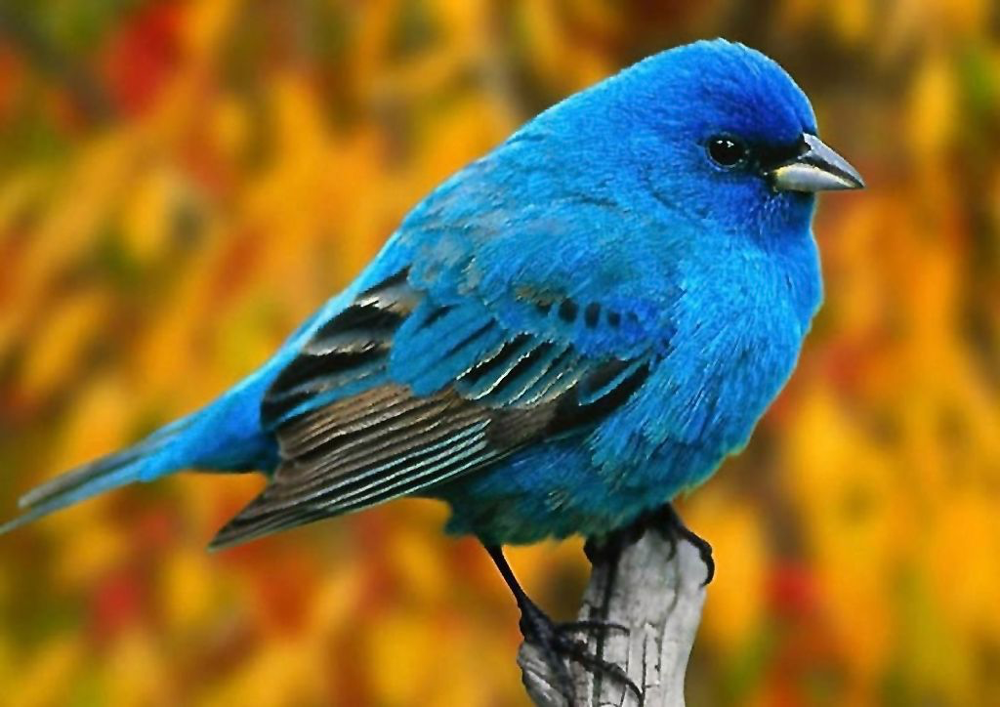

**Импорты**

In [ ]:
import os, math
import numpy as np
import matplotlib.pyplot as plt
plt.set_cmap('cividis')
%matplotlib inline
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.data as data
import torch.optim as optim
import torchvision
from torchvision import transforms

from datasets import load_dataset

try:
    import pytorch_lightning as pl
except ModuleNotFoundError:  # в Colab Lightning по умолчанию не установлен
    !pip install --quiet pytorch-lightning>=1.4
    import pytorch_lightning as pl
from pytorch_lightning.callbacks import LearningRateMonitor, ModelCheckpoint

CHECKPOINT_PATH = "./saved_models/ar_models"

pl.seed_everything(42)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda:0") if torch.cuda.is_available() else torch.device("cpu")
print("Using device", device)

INFO:lightning_fabric.utilities.seed:Seed set to 42


Using device cuda:0


<Figure size 640x480 with 0 Axes>

In [ ]:
birds_ds = load_dataset("weiywang/CUB_200_2011_CAP", split="train")

README.md:   0%|          | 0.00/372 [00:00<?, ?B/s]

data/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  385MB            

data/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  387MB            

data/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  376MB            

data/train-00002-of-00003.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/11787 [00:00<?, ? examples/s]

### UPD: VQ-VAE

VQ-VAE - это автоэнкодер, который позволяет сжимать большие входные изображения в дискретное латентное пространство (последовательность кодов) и декодировать их обратно (см. рис).

<img src="https://substackcdn.com/image/fetch/$s_!dRiM!,f_auto,q_auto:good,fl_progressive:steep/https%3A%2F%2Fsubstack-post-media.s3.amazonaws.com%2Fpublic%2Fimages%2F81630fcc-b23e-4f06-831f-690aff70e03b_1215x476.png" width="800" height="400">

VQ-VAE состоит из трех частей. Энкодер кодирует входное изображение $x \in \mathbb{R}^{B \times C \times H \times W}$ в непрерывное латентное пространство $z_e \in \mathbb{R}^{B \times D \times H_{h} \times W_{h}}$. Quantizer смотрит на каждый вектор из $z_e$ ($H_{h} \times W_{h}$ штук длины $D$) и заменяет их на ближайший похожий вектор из словаря-векторов (codebook), который обучался вместе с моделью. Сам $z_e$после такой операции заменяется на $z_q$ (те же размеры, но каждый вектор заменен на ближайшего из кодбука). $z_q$ можно хранить либо как непрерывный тензор $\mathbb{R}^{B \times D \times H_{h} \times W_{h}}$, либо просто хранить $B \times  H_{h} \times W_{h}$ дискретных индексов из кодбука, где индексы соответствуют номеру вектора в кодбуке (для примера, если у нас 4096 векторов в кодбуке и мы $z_e$ заменили на вектора на местах $1, 2000, 2, 10$ из кодбука, то теперь $z_q$ в дискретном виде это просто массив $1, 200, 2, 10$). Декодер, последняя часть VQ-VAE, берет $z_q$ и переводит из кодов обратно в вектора из кодбука (если $z_q$ был в виде кодов, а не векторов) и прогоняет $z_q$ через набор слоев, чтобы получить изображение $\hat{x} \simeq x$.


$H_{h} \times W_{h}$ как правило сильно меньше оригинальных $H \times W$, поэтому многие генеративные модели используют VQ-VAE для генерации высококачественных изображений без значительного усложнения вычислительной сложности. Действительно, если вместо авторегрессионной генерации $С \times H \times W$, где $H, W \ge 128$ мы будем работать с дискретным тензором $H_{h} \times W_{h}$, где $H_h, W_h \le 32$, то мы сможем генерировать качественные изображения с той же вычислительной сложностью как если бы сделали resize изначальных картинок в $32\times32$, но при этом не теряем в качестве изображений (ведь финальное изображение получается прогоном кодов через декодер).

Давайте посмотрим как это работает:

In [ ]:
# Скачаем предобученную VQ-VAE

from diffusers import VQModel
vqvae = VQModel.from_pretrained("microsoft/vq-diffusion-ithq", subfolder="vqvae")
vqvae.to(device)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/606 [00:00<?, ?B/s]

An error occurred while trying to fetch microsoft/vq-diffusion-ithq: microsoft/vq-diffusion-ithq does not appear to have a file named diffusion_pytorch_model.safetensors.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


vqvae/diffusion_pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  256MB            

vqvae/diffusion_pytorch_model.bin: downloading bytes:           |  0.00B            

VQModel(
  (encoder): Encoder(
    (conv_in): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (down_blocks): ModuleList(
      (0): DownEncoderBlock2D(
        (resnets): ModuleList(
          (0-1): 2 x ResnetBlock2D(
            (norm1): GroupNorm(32, 64, eps=1e-06, affine=True, bias=True)
            (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (norm2): GroupNorm(32, 64, eps=1e-06, affine=True, bias=True)
            (dropout): Dropout(p=0.0, inplace=False)
            (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (nonlinearity): SiLU()
          )
        )
        (downsamplers): ModuleList(
          (0): Downsample2D(
            (conv): Conv2d(64, 64, kernel_size=(3, 3), stride=(2, 2))
          )
        )
      )
      (1): DownEncoderBlock2D(
        (resnets): ModuleList(
          (0): ResnetBlock2D(
            (norm1): GroupNorm(32, 64, eps=1e-06, affine=True, bias=Tru

Скачаем картинку для примера

Я скачал другую картинку, ибо изначальная не скачивалась

In [ ]:
!wget "https://commons.wikimedia.org/wiki/Special:FilePath/Myzomela_sanguinolenta_1_-_Windsor_Downs_Nature_Reserve.jpg" -O example.jpg

--2026-11-22 14:17:32--  https://commons.wikimedia.org/wiki/Special:FilePath/Myzomela_sanguinolenta_1_-_Windsor_Downs_Nature_Reserve.jpg
Resolving commons.wikimedia.org (commons.wikimedia.org)... 198.35.26.224, 2620:0:863:ed1a::1
Connecting to commons.wikimedia.org (commons.wikimedia.org)|198.35.26.224|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://commons.wikimedia.org/wiki/Special:Redirect/file/Myzomela_sanguinolenta_1_-_Windsor_Downs_Nature_Reserve.jpg [following]
--2026-11-22 14:17:32--  https://commons.wikimedia.org/wiki/Special:Redirect/file/Myzomela_sanguinolenta_1_-_Windsor_Downs_Nature_Reserve.jpg
Reusing existing connection to commons.wikimedia.org:443.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://upload.wikimedia.org/wikipedia/commons/3/3f/Myzomela_sanguinolenta_1_-_Windsor_Downs_Nature_Reserve.jpg?utm_source=commons.wikimedia.org&utm_campaign=index&utm_content=original [following]
--2026-11-22 14:17:

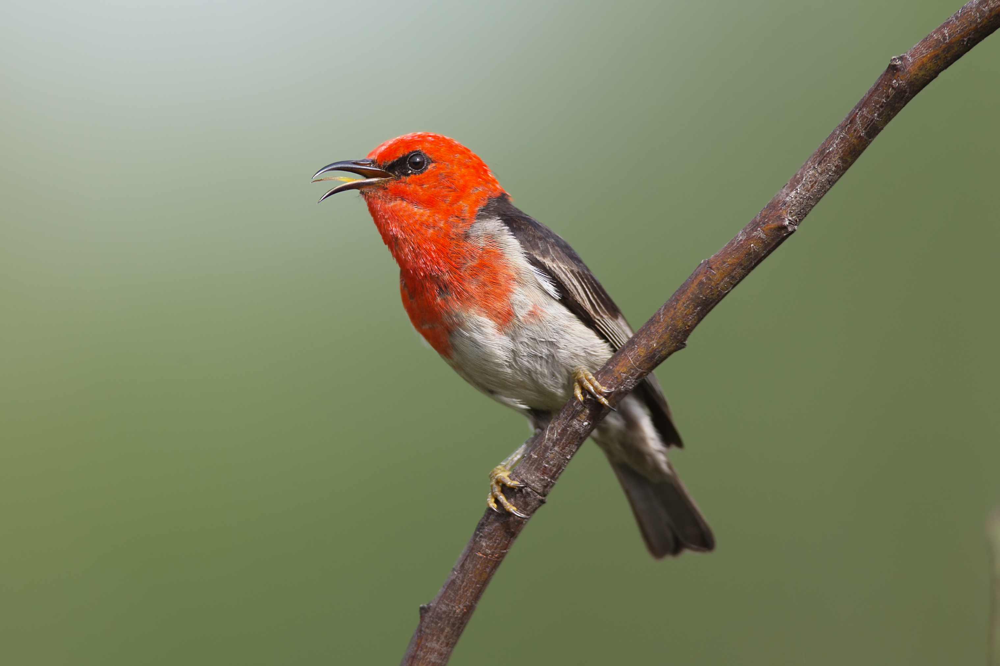

In [ ]:
from PIL import Image

img = Image.open("example.jpg")
img

VQ-VAE этот работает на изображениях $256\times 256$, поэтому ресайзим

In [ ]:
x = transforms.Resize((256, 256))(img)
x = transforms.ToTensor()(x)
x.shape

torch.Size([3, 256, 256])

Код для получения кодов и декодирования изображения:

In [ ]:
def img_to_codes(x, vqvae):
    if x.ndim != 4:
        x = x.unsqueeze(0)
    # для нормализации вход не [0, 1], а [-1, 1]
    x = x * 2 - 1
    # применяем энкодер
    latent = vqvae.encode(x).latents
    # получаем z_q и соответствующие коды
    quant, commit_loss, (_, _, indices) = vqvae.quantize(latent)
    # коды тут flatten, решейпим обратно
    B, _, Hc, Wc = latent.shape
    if indices.dim() == 1:
        codes = indices.view(B, Hc, Wc)
    else:
        codes = indices
    return codes

def codes_to_img(codes, vqvae):
    B, Hc, Wc = codes.shape
    codes = codes.view(-1)
    # получаем непрерывное z_q из соответствующих кодов,
    # смотря на вектора из кодбука по индексам
    quant = vqvae.quantize.get_codebook_entry(
        codes,
        shape=(B, Hc, Wc, vqvae.quantize.vq_embed_dim)  # (B, H, W, C)
    )
    # декодируем
    quant2 = vqvae.post_quant_conv(quant)
    dec = vqvae.decoder(quant2, quant if vqvae.config.norm_type == "spatial" else None)
    return (dec + 1) / 2

Применим:

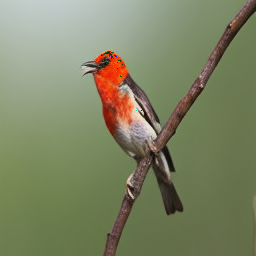

In [ ]:
codes = img_to_codes(x.to(device), vqvae)
hat_x = codes_to_img(codes, vqvae)
transforms.ToPILImage()(hat_x[0])

In [ ]:
hat_x.shape

torch.Size([1, 3, 256, 256])

Видим, что у нас получилось довольно хорошо восстановить изображения из кодов. Но какие размеры у `codes`?

In [ ]:
codes.shape

torch.Size([1, 32, 32])

$B=1$, т.е. вместо $3\times 256\times 256$ (RGB) мы получаем всего лишь $32\times 32$.

Раньше, дискретных значений было в одном пикселе было $3 \cdot 256$ (цвета в RGB по каждому каналу). Теперь кол-во дискретных значения задается количеством кодов в кодбуке vqvae $N_q$

In [ ]:
vqvae.config.num_vq_embeddings

4096

Как и прежде, мы можем генерировать подобные дискретные тензоры авторегрессионно с помощью PixelCNN, но если раньше мы работали в пространстве изображений, то теперь будем работать в латентном. Как и раньше, мы будем считать, что $32\times32$ тензор это последовательность токенов со значениями из $[0, N_q-1]$, которую мы считываем построчно слево направо. Наш PixelCNN, как и раньше, будет смотреть только на предыдущие токены, чтобы генерировать новый. Модель каждый шаг будет предсказывать вероятностное распределение на словаре: $[0, N_q-1]$

То есть, все буквально, как и раньше, но вместо RGB изображений, мы будем генерировать `codes`. Чтобы получить RGB, мы просто прокинем codes через декодер VQ-VAE и получим RGB изображений в высоком разрешении.

P.S. Поскольку VQ-VAE сильно сжимает изображение, мы заодно избавляемся от высокочастотного шума, который присутствует в цветных натуральных изображениях и мешает авторегрессионным генераторам делать хорошую генерацию. RGB шум из-за слишком разнообразного фона на картинках птиц. VQ-VAE, за счет сжатия, делает каждый токен очень значимым (нет двух соседних токенов, которые по сути отвечают лишь за две соседние маленькие точки фона, мешая PixelCNN обучиться). Действительно, если изначально картинка была с стороной 256, а стала с 32 в  `codes`, то каждый токен отвечает за участок размера $8\times8$, что куда более значимо, чем один пиксель в исходном изображении. Можно было бы сказать, что такого же эффекта "значимости" можно было бы добиться просто resize в $32\times 32$ RGB картинки, но PixelCNN путался бы из-за цветов (3 канала в RGB, в `codes` нет каналов), а также сами пиксели имели бы лишь поверхностное значение. В VQ-VAE токены смоделированы специально для сжатия и восстановления обратно в $256\times 256$, поэтому каждый токен содержит в себе более глубокую и детальную информацию, чем просто resize-нутый пиксель.

### Задание 2 (1 балл).

Скачайте любую версию предобученного CLIP на ваш вкус, примените текстовый кодировщик к описаниям птиц из датасета (столбец "text") и сохраните получившиеся эмбеддинги.

Возьмите из датасета две картинки с визуально похожими птицами и посчитайте косинусную близость эмбеддингов подписей к этим фото, оцените корректность результата.

In [ ]:
# Скачаем CLIP
from transformers import AutoTokenizer, CLIPTextModelWithProjection

model_id = "openai/clip-vit-base-patch32"
tokenizer = AutoTokenizer.from_pretrained(model_id, use_fast=True)
text_encoder = CLIPTextModelWithProjection.from_pretrained(model_id).to(device).eval()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] CLIPTextModelWithProjection LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
vision_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
vision_model.pre_layrnorm.weight                               | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.mlp.fc1.weight            | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
vision_m

Посмотрим на максимальное количество токенов в энкодере и на их среднее количество в текстах

In [ ]:
sizes = []
random_indeces = np.random.choice(len(birds_ds), size=200)
for idx in random_indeces:
  txt = birds_ds[idx]["text"]
  sizes.append(tokenizer(txt, truncation=False, return_tensors="pt")["input_ids"].shape[1])

print(f"Среднее количество токенов в описаниях: {np.mean(sizes)}")
print(f"Максимальное количество токенов в энкодере: {text_encoder.config.max_position_embeddings}")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (150 > 77). Running this sequence through the model will result in indexing errors


Среднее количество токенов в описаниях: 178.3
Максимальное количество токенов в энкодере: 77


Модель "openai/clip-vit-base-patch32" имеет ограниченный размер контекста, максимум 77 токенов, но тексты в описаниях раза в 2 больше, чтобы эмбеддинг содержал больше информации из текста, мы "нарежем" текст по токенам, а полученные эмбеддинги усредним.

In [ ]:
@torch.inference_mode()
def encode_texts(texts):
    """Возвращает средний CLIP-эмбеддинг фрагментов каждого описания."""
    inputs = tokenizer(
        texts,
        max_length=text_encoder.config.max_position_embeddings,
        truncation=True,
        return_overflowing_tokens=True,  # сохраняем продолжение каждого текста
        stride=0,
        padding=True,
        return_tensors="pt",
    )

    text_ids = inputs.pop("overflow_to_sample_mapping")

    chunk_embeds = text_encoder(**inputs.to(device)).text_embeds.float().cpu()

    # Один вектор на текст
    text_embeds = torch.stack([
        chunk_embeds[text_ids == i].mean(dim=0)
        for i in range(len(texts))
    ])

    return {"text_embedding": text_embeds.numpy()}

# Создадим датасет с эмбеддингами описаний
birds_with_embeddings = birds_ds.map(
    encode_texts,
    batched=True,
    batch_size=32,
    input_columns=["text"],
)

Map:   0%|          | 0/11787 [00:00<?, ? examples/s]

Для примера возьмём двух птиц одинакового лейбла и получим косинусную близость их эмбеддингов

Label: Olive Sided Flycatcher


Filter:   0%|          | 0/11787 [00:00<?, ? examples/s]

Text 1: the chest and outer layer of the bird are white and grey.this bird has a white breast/belly with brown feathers otherwise.this is a dark brown bird with a white patch from its breast to its abdomen.this brown and white bird has a short beak and short legs.this bird has a speckled belly and breast with a short pointy bill.this bird is brown with white and has a long, pointy beak.this bird has wings that are black and has a white bellythis bird is brown with white and has a long, pointy beak.this bird has a white breast and throat, a black crown and nape, and a sharp black beak.this bird is mostly brown except for a patch of white on its belly and a band of white around its neck.
Text 2: this small bird has brown and white feathers, with a small beak and black eyes.this is a small brown and white bird with a black pointy beakthis bird is petite in stature with a white breast and brown feathers.this gray bird had a white stripe through the chest and belly and a short black bill.th

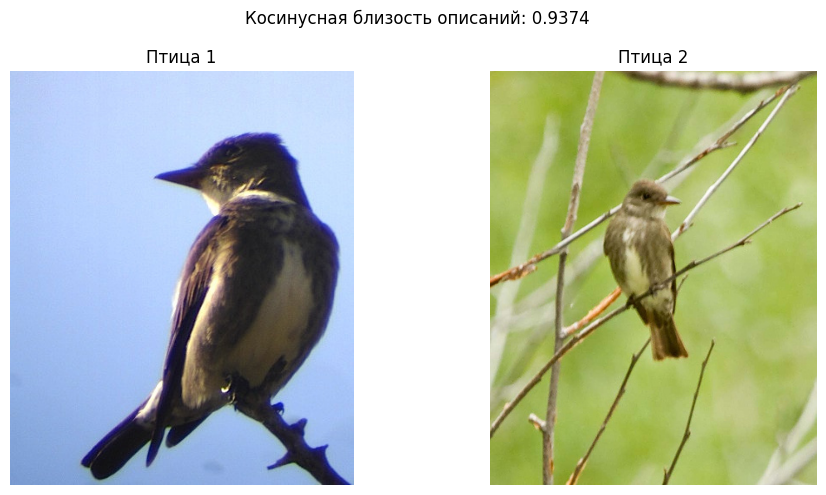

In [ ]:
np.random.seed(42)
random_index = np.random.randint(len(birds_with_embeddings))

random_label = birds_with_embeddings[random_index]["label"]
print(f"Label: {random_label}")

random_pair = birds_with_embeddings.filter(lambda x: x["label"] == random_label).shuffle(seed=42).select(range(2))

print(f"Text 1: {random_pair[0]['text']}")
print(f"Text 2: {random_pair[1]['text']}")

emb_1 = torch.as_tensor(random_pair[0]["text_embedding"], dtype=torch.float32)
emb_2 = torch.as_tensor(random_pair[1]["text_embedding"], dtype=torch.float32)

cosine_sim = F.cosine_similarity(emb_1, emb_2, dim=-1).item()

# Покажем изображения птиц
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for i, ax in enumerate(axes):
    ax.imshow(random_pair[i]["image"])
    ax.set_title(f"Птица {i + 1}")
    ax.axis("off")

fig.suptitle(f"Косинусная близость описаний: {cosine_sim:.4f}")
plt.tight_layout()
plt.show()

Птицы похожи как визуально, так и по текстовому описанию (белое брюшко, коричневые перья...). Результат корректен.

### Задание 3 (0.5 балла).

Соберите картинки и получившиеся эмбеддинги в датасеты. Сохраните два датасета: один только с изображениями, другой - с изображениями и эмбеддингами подписей.

- Сконвертируйте картинки в соответствующие `codes` (используйте функции выше)

Hint: внимательно посмотрите на кол-во каналов в изображениях датасета и размеры картинок, предобработайте картинки перед подачей в VQ-VAE

Hint 2: сначала используется сабсет из вашего датасета для дебага, потому что датасет конвертируется долго, после дебага используйте весь

In [ ]:
vqvae.eval()

@torch.inference_mode()
def encode_images(images):
  """Функция для получения кодов из изображений с помощью VQ-VAE"""
  preprocess = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
  ])
  # Делаем RGB преобразование для одноканальных картинок
  pixels = [preprocess(img.convert("RGB")) for img in images]
  x = torch.stack(pixels, dim=0).to(device) # [B, 3, 256, 256]

  codes = img_to_codes(x, vqvae)
  return {"vqvae-codes": codes.cpu().numpy()}

birds_ds_encoded = birds_with_embeddings.map(
    encode_images,
    input_columns="image",
    batched=True,
    batch_size=128,
)

Map:   0%|          | 0/11787 [00:00<?, ? examples/s]

In [ ]:
# Сохраним датасеты на HuggingFace
codes_ds = birds_ds_encoded.select_columns(["vqvae-codes"])
codes_clip_ds = birds_ds_encoded.select_columns(["vqvae-codes", "text_embedding"])

for name, ds in [("codes", codes_ds), ("codes_clip", codes_clip_ds)]:
    ds.push_to_hub(
        "DaniilSilver/hse-birds-pixelcnn",
        config_name=name,
        split="train",
        private=False
    )

Setting num_proc from 1 back to 1 for the train split to disable multiprocessing as it only contains one shard.


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  /tmp/tmpdgeo2jot.parquet    :   1%|1         | 1.32MB / 98.5MB            

... (4 outputs left out)

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  /tmp/tmpclp6y33r.parquet    :  13%|#3        | 16.0MB /  123MB            

Validating                    :           |   0%            

### Задание 4 (2 балла).

- Обучите [модель (PixelCNN)](https://colab.research.google.com/drive/1EIsBxlTcz3ZB0j-ZxN1gWD2dSQq6krPj?usp=sharing) только на `codes` птиц. Модифицируйте размерности тензоров в модели, где это необходимо - чтобы она корректно работала с данными изображениями (обратите внимание на то, какие дискретные числа должны предсказывать ваша модель)

- Сделайте обучаемый `nn.Embedding` для `codes` перед подачей в слои свертки

- Вы можете менять гиперпараметры для улучшения качества генерации

- Выведите на экран 10 сгенерированных картинок, оцените результат, напишите выводы

Hint: добавьте конвертацию кодов в изображения в функцию отрисовки картинок, а не в `sample`.

#### PixelCNN (uncond)

In [ ]:
# Возьмём архитектуру PixelCNN из семинарского занятия и немного изменим её
class MaskedConvolution(nn.Module):

    def __init__(self, c_in, c_out, mask, **kwargs):
        """
        Implements a convolution with mask applied on its weights.
        Inputs:
            c_in - Number of input channels
            c_out - Number of output channels
            mask - Tensor of shape [kernel_size_H, kernel_size_W] with 0s where
                   the convolution should be masked, and 1s otherwise.
            kwargs - Additional arguments for the convolution
        """
        super().__init__()
        # For simplicity: calculate padding automatically
        kernel_size = (mask.shape[0], mask.shape[1])
        dilation = 1 if "dilation" not in kwargs else kwargs["dilation"]
        padding = tuple([dilation*(kernel_size[i]-1)//2 for i in range(2)])
        # Actual convolution
        self.conv = nn.Conv2d(c_in, c_out, kernel_size, padding=padding, **kwargs)

        # Mask as buffer => it is no parameter but still a tensor of the module
        # (must be moved with the devices)
        self.register_buffer('mask', mask[None,None])

    def forward(self, x):
      c = self.conv
      return F.conv2d(
          x, c.weight * self.mask, c.bias,
          stride=c.stride, padding=c.padding,
          dilation=c.dilation, groups=c.groups,
      )

class VerticalStackConvolution(MaskedConvolution):

    def __init__(self, c_in, c_out, kernel_size=3, mask_center=False, **kwargs):
       # Создаётся квадратная матрица из единиц (kernel_size × kernel_size), которая будет маской.
       # Все элементы ниже центральной строки зануляются (=0) → это значит, что фильтр не может смотреть вниз
       # (т.е. на пиксели ниже текущего).
        mask = torch.ones(kernel_size, kernel_size)
        mask[kernel_size//2+1:,:] = 0

       # Если mask_center=True, то обнуляется центральная строка, то есть пиксель не видит даже себя самого.
       # Это используется при самой первой свёртке, чтобы не допустить “подглядывания” текущего значения.
        if mask_center:
            mask[kernel_size//2,:] = 0

        super().__init__(c_in, c_out, mask, **kwargs)

class HorizontalStackConvolution(MaskedConvolution):

    def __init__(self, c_in, c_out, kernel_size=3, mask_center=False, **kwargs):
        mask = torch.ones(1,kernel_size)
        mask[0,kernel_size//2+1:] = 0

        if mask_center:
            mask[0,kernel_size//2] = 0

        super().__init__(c_in, c_out, mask, **kwargs)


class GatedMaskedConv(nn.Module):

    def __init__(self, c_in, **kwargs):
        """
        Gated Convolution block implemented the computation graph shown above.
        """
        super().__init__()
        self.conv_vert = VerticalStackConvolution(c_in, c_out=2*c_in, **kwargs)
        self.conv_horiz = HorizontalStackConvolution(c_in, c_out=2*c_in, **kwargs)
        self.conv_vert_to_horiz = nn.Conv2d(2*c_in, 2*c_in, kernel_size=1, padding=0)
        self.conv_horiz_1x1 = nn.Conv2d(c_in, c_in, kernel_size=1, padding=0)

    def forward(self, v_stack, h_stack):
        # Vertical stack (left)
        v_stack_feat = self.conv_vert(v_stack)
        v_val, v_gate = v_stack_feat.chunk(2, dim=1)
        v_stack_out = torch.tanh(v_val) * torch.sigmoid(v_gate)

        # Horizontal stack (right)
        h_stack_feat = self.conv_horiz(h_stack)
        h_stack_feat = h_stack_feat + self.conv_vert_to_horiz(v_stack_feat)
        h_val, h_gate = h_stack_feat.chunk(2, dim=1)
        h_stack_feat = torch.tanh(h_val) * torch.sigmoid(h_gate)
        h_stack_out = self.conv_horiz_1x1(h_stack_feat)
        h_stack_out = h_stack_out + h_stack

        return v_stack_out, h_stack_out


class PixelCNN(pl.LightningModule):

    def __init__(
        self,
        num_codes,
        c_hidden=64,
        embed_dim=32,
        *,
        dilations = (1, 2, 4, 8, 4, 8, 4, 2, 1),
        optimizer_cls=torch.optim.Adam,
        optimizer_kwargs=None,
        scheduler_cls=None,
        scheduler_kwargs=None
        ):
        super().__init__()
        self.save_hyperparameters()

        self.optimizer_cls = optimizer_cls
        self.scheduler_cls = scheduler_cls
        self.optimizer_kwargs = dict(optimizer_kwargs or {})
        self.scheduler_kwargs = dict(scheduler_kwargs or {})


        # Инициализируем эмбеддинги кодбуков
        self.embedding = nn.Embedding(num_codes, embed_dim)
        self.conv_vstack = VerticalStackConvolution(embed_dim, c_hidden, mask_center=True)
        self.conv_hstack = HorizontalStackConvolution(embed_dim, c_hidden, mask_center=True)

        # Convolution block of PixelCNN. We use dilation instead of downscaling
        self.conv_layers = nn.ModuleList(GatedMaskedConv(c_hidden, dilation=d) for d in dilations)
        # Output classification convolution (1x1) into codebok size
        self.conv_out = nn.Conv2d(c_hidden, num_codes, kernel_size=1, padding=0)

    def forward(self, x):
        """
        Forward image through model and return logits for each pixel.
        Inputs:
            x - codes tensor with integer values between 0 and num_codes-1
            [B, H, W]
        """

        x = self.embedding(x).permute(0, 3, 1, 2) # [B, D, H, W]
        # Initial convolutions
        v_stack = self.conv_vstack(x)
        h_stack = self.conv_hstack(x)
        # Gated Convolutions
        for layer in self.conv_layers:
            v_stack, h_stack = layer(v_stack, h_stack)
            v_stack = F.elu(v_stack)
            h_stack = F.elu(h_stack)
        # 1x1 classification convolution
        # Apply ELU before 1x1 convolution for non-linearity on residual connection
        out = self.conv_out(F.elu(h_stack)) # [B, num_codes, H, W]
        return out

    def calc_likelihood(self, x):
        # Forward pass with bpd likelihood calculation
        pred = self.forward(x)
        nll = F.cross_entropy(pred, x)
        return nll


    @torch.inference_mode()
    def sample(self, shape, temperature=1.0):
        if temperature < 0:
            raise ValueError("temperature должна быть неотрицательной")

        _, height, width = shape
        codes = torch.zeros(shape, dtype=torch.long, device=self.device)

        for row in tqdm(range(height), desc="Генерация", leave=False):
            for col in range(width):
                logits = self(codes[:, :row + 1, :])[:, :, row, col]
                logits_temp = logits / max(temperature, 1e-4)
                probs = F.softmax(logits_temp, dim=-1)

                codes[:, row, col] =  torch.multinomial(probs, num_samples=1).squeeze(dim=-1)

        return codes


    def configure_optimizers(self):
      optimizer = self.optimizer_cls(self.parameters(), **self.optimizer_kwargs)
      dummy_scheduler = torch.optim.lr_scheduler.ConstantLR(optimizer, factor=1.0, total_iters=1)
      scheduler = self.scheduler_cls(optimizer, **self.scheduler_kwargs) if self.scheduler_cls else dummy_scheduler
      return {"optimizer": optimizer, "lr_scheduler": scheduler}

    def _step(self, batch, stage):
        codes = batch["vqvae-codes"].long()
        nll = self.calc_likelihood(codes)
        self.log(f"{stage}_bpd", nll /math.log(2), on_step=False, on_epoch=True,
                prog_bar=True, batch_size=codes.size(0))
        return nll

    def training_step(self, batch, batch_idx):
        return self._step(batch, "train")

    def validation_step(self, batch, batch_idx):
        self._step(batch, "val")

    def test_step(self, batch, batch_idx):
        self._step(batch, "test")

In [ ]:
class MaskedConvolution(nn.Module):
    def __init__(self, c_in, c_out, mask, *, dilation=1):
        super().__init__()

        kernel_size = tuple(mask.shape)
        padding = tuple(dilation * (k // 2) for k in kernel_size)

        self.conv = nn.Conv2d(
            c_in,
            c_out,
            kernel_size=kernel_size,
            padding=padding,
            dilation=dilation,
        )
        self.register_buffer("mask", mask[None, None])

    def forward(self, x):
        conv = self.conv
        return F.conv2d(
            x,
            conv.weight * self.mask,
            conv.bias,
            stride=conv.stride,
            padding=conv.padding,
            dilation=conv.dilation,
            groups=conv.groups,
        )


class VerticalStackConvolution(MaskedConvolution):
    def __init__(self, c_in, c_out, kernel_size=3, mask_center=False, **kwargs):
        mask = torch.ones(kernel_size, kernel_size)
        center = kernel_size // 2

        mask[center + 1:, :] = 0
        if mask_center:
            mask[center, :] = 0

        super().__init__(c_in, c_out, mask, **kwargs)


class HorizontalStackConvolution(MaskedConvolution):
    def __init__(self, c_in, c_out, kernel_size=3, mask_center=False, **kwargs):
        mask = torch.ones(1, kernel_size)
        center = kernel_size // 2

        mask[:, center + 1:] = 0
        if mask_center:
            mask[:, center] = 0

        super().__init__(c_in, c_out, mask, **kwargs)


class ChannelLayerNorm(nn.LayerNorm):
    def forward(self, x):
        # LayerNorm применяется к C каналам отдельно в каждой позиции.
        # [B, C, H, W] -> [B, H, W, C] -> [B, C, H, W]
        return super().forward(x.movedim(1, -1)).movedim(-1, 1)


class ResidualGatedBlock(nn.Module):
    def __init__(self, channels, dilation=1):
        super().__init__()

        self.norm_v = ChannelLayerNorm(channels)
        self.norm_h = ChannelLayerNorm(channels)

        self.conv_v = VerticalStackConvolution(
            channels, 2 * channels, dilation=dilation
        )
        self.conv_h = HorizontalStackConvolution(
            channels, 2 * channels, dilation=dilation
        )

        self.proj_v = nn.Conv2d(channels, channels, kernel_size=1)
        self.v_to_h = nn.Conv2d(channels, 2 * channels, kernel_size=1)
        self.proj_h = nn.Conv2d(channels, channels, kernel_size=1)

    def forward(self, v_stack, h_stack):
        # Вертикальный стек
        v_features = self.conv_v(self.norm_v(v_stack))
        v_value, v_gate = v_features.chunk(2, dim=1)
        v_update = torch.tanh(v_value) * torch.sigmoid(v_gate)
        v_stack = v_stack + self.proj_v(v_update)

        # Горизонтальный стек получает обновлённый вертикальный контекст.
        h_features = self.conv_h(self.norm_h(h_stack)) + self.v_to_h(v_stack)
        h_value, h_gate = h_features.chunk(2, dim=1)
        h_update = torch.tanh(h_value) * torch.sigmoid(h_gate)
        h_stack = h_stack + self.proj_h(h_update)

        return v_stack, h_stack


class PixelCNNV2(pl.LightningModule):
    def __init__(
        self,
        num_codes,
        c_hidden=160,
        embed_dim=64,
        *,
        dilations=(1, 2, 4, 8, 4, 8, 4, 1, 2, 1),
        head_dim=384,
        optimizer_cls=torch.optim.Adam,
        optimizer_kwargs=None,
        scheduler_cls=None,
        scheduler_kwargs=None,
    ):
        super().__init__()
        self.save_hyperparameters()

        self.embedding = nn.Embedding(num_codes, embed_dim)

        # Первые свёртки закрывают доступ к текущему входному коду.
        self.first_v = VerticalStackConvolution(
            embed_dim, c_hidden, mask_center=True
        )
        self.first_h = HorizontalStackConvolution(
            embed_dim, c_hidden, mask_center=True
        )

        self.blocks = nn.ModuleList(
            ResidualGatedBlock(c_hidden, dilation=d) for d in dilations
        )

        self.head = nn.Sequential(
            ChannelLayerNorm(c_hidden),
            nn.Conv2d(c_hidden, head_dim, kernel_size=1),
            nn.SiLU(),
            nn.Conv2d(head_dim, num_codes, kernel_size=1),
        )

        self.register_buffer("start_logit_bias", torch.zeros(num_codes))

    def forward(self, codes):
        # codes: [B, H, W]
        x = self.embedding(codes).movedim(-1, 1)  # [B, D, H, W]

        v_stack = self.first_v(x)
        h_stack = self.first_h(x)

        for block in self.blocks:
            v_stack, h_stack = block(v_stack, h_stack)

        logits = self.head(h_stack)  # [B, num_codes, H, W]
        logits[:, :, 0, 0] = logits[:, :, 0, 0] + self.start_logit_bias
        return logits

    @torch.inference_mode()
    def sample(self, shape, temperature=1.0):
        if not math.isfinite(temperature) or temperature < 0:
            raise ValueError("Температура должна быть конечной и >= 0")

        _, height, width = shape
        codes = torch.zeros(shape, dtype=torch.long, device=self.device)

        for row in tqdm(range(height), desc="Генерация", leave=False):
            for col in range(width):
                logits = self(codes[:, :row + 1, :])[:, :, row, col]

                if temperature == 0:
                    next_code = logits.argmax(dim=1)
                else:
                    probs = F.softmax(
                        logits.float() / max(temperature, 1e-4), dim=1
                    )
                    next_code = torch.multinomial(probs, 1).squeeze(1)

                codes[:, row, col] = next_code

        return codes

    def configure_optimizers(self):
        hp = self.hparams
        optimizer = hp.optimizer_cls(
            self.parameters(), **(hp.optimizer_kwargs or {})
        )

        if hp.scheduler_cls is None:
            return optimizer

        scheduler = hp.scheduler_cls(optimizer, **(hp.scheduler_kwargs or {}))
        return {
            "optimizer": optimizer,
            "lr_scheduler": scheduler,
            "monitor": "val_bpd",
        }

    def calc_likelihood(self, x):
        pred = self.forward(x)
        nll = F.cross_entropy(pred, x)
        return nll

    def _step(self, batch, stage):
        codes = batch["vqvae-codes"].long()
        nll = self.calc_likelihood(codes)
        self.log(f"{stage}_bpd", nll /math.log(2), on_step=False, on_epoch=True,
                prog_bar=True, batch_size=codes.size(0))
        return nll

    def training_step(self, batch, batch_idx):
        return self._step(batch, "train")

    def validation_step(self, batch, batch_idx):
        self._step(batch, "val")

    def test_step(self, batch, batch_idx):
        self._step(batch, "test")

#### model train interface

In [ ]:
from torch.utils.data import DataLoader

@torch.inference_mode()
def show_samples(model, vqvae, height, width, temperature=1.0, batch_size=10, cond=None):
    """Функция для отрисовки картинок"""
    vqvae.eval()
    model.to(device).eval()

    if cond is None:
      codes = model.sample((batch_size, height, width), temperature)  # [10, H, W]
    else:
      # Для генерации по условию
      codes = model.sample((len(cond), height, width), cond=cond.to(device), temperature=temperature)

    fig, axes = plt.subplots(2, 5, figsize=(12, 5))
    for ax, grid in zip(axes.flat, codes):
        image = codes_to_img(grid.unsqueeze(0), vqvae)[0].clamp(0, 1)
        ax.imshow(image.permute(1, 2, 0).cpu())
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def train_model(model, train_ds, val_ds, test_ds, *, epochs, batch_size=8, conditional=False):
    """Интерфейс для обучения """

    columns = ["vqvae-codes", "text_embedding"] if conditional else ["vqvae-codes"]
    path = os.path.join(CHECKPOINT_PATH, "PixelCNN" if not conditional else "PixelCNN_cond")
    os.makedirs(path, exist_ok=True)

    def make_loader(ds, shuffle=False):
        ds = ds.with_format("torch", columns=columns)
        return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=2, pin_memory=True)

    trainer = pl.Trainer(
        default_root_dir=path,
        accelerator="gpu" if torch.cuda.is_available() else "cpu",
        devices=1,
        max_epochs=epochs,
        callbacks=[ModelCheckpoint(save_weights_only=True, mode="min", monitor="val_bpd"),
          LearningRateMonitor("epoch")]
    )

    trainer.fit(model, make_loader(train_ds, shuffle=True), make_loader(val_ds))
    test_metrics = trainer.test(model, dataloaders=make_loader(test_ds))[0]

    return model, test_metrics

#### Запуск обучения

In [ ]:
# Загрузим датасет с hf
codes_ds = load_dataset(
    "DaniilSilver/hse-birds-pixelcnn",
    name="codes",
    split="train"
)
# split train, val, test
splitted_ds = codes_ds.train_test_split(test_size=0.1, seed=42)
train_val_ds = splitted_ds["train"].train_test_split(test_size=0.2, seed=42)

train_ds = train_val_ds["train"]
val_ds = train_val_ds["test"]
test_ds = splitted_ds["test"]

sanity_ds = train_ds.select(range(100))

print(f"Train size: {len(train_ds)}")
print(f"Val size: {len(val_ds)}")
print(f"Test size: {len(test_ds)}")

README.md:   0%|          | 0.00/660 [00:00<?, ?B/s]

codes/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 98.5MB            

codes/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/11787 [00:00<?, ? examples/s]

Train size: 8486
Val size: 2122
Test size: 1179


**Sanity-check**

In [ ]:
num_codes = vqvae.config.num_vq_embeddings

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type                       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ embedding │ Embedding                  │  262 K │ train │     0 │
│ 1 │ first_v   │ VerticalStackConvolution   │ 92.3 K │ train │     0 │
│ 2 │ first_h   │ HorizontalStackConvolution │ 30.9 K │ train │     0 │
│ 3 │ blocks    │ ModuleList                 │  7.2 M │ train │     0 │
│ 4 │ head      │ Sequential                 │  1.6 M │ train │     0 │
└───┴───────────┴────────────────────────────┴────────┴───────┴───────┘

Trainable params: 9.2 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 9.2 M                                                                                                
Total estimated model params size (MB): 36.847                                                                     
Modules in train mode: 111                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/loops/fit_loop.py:321: The number of training batches (4)
is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you 
want to see logs for the training epoch.

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=30` reached.


INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_bpd          │     22.41965103149414     │
└───────────────────────────┴───────────────────────────┘

Генерация:   0%|          | 0/32 [00:00<?, ?it/s]

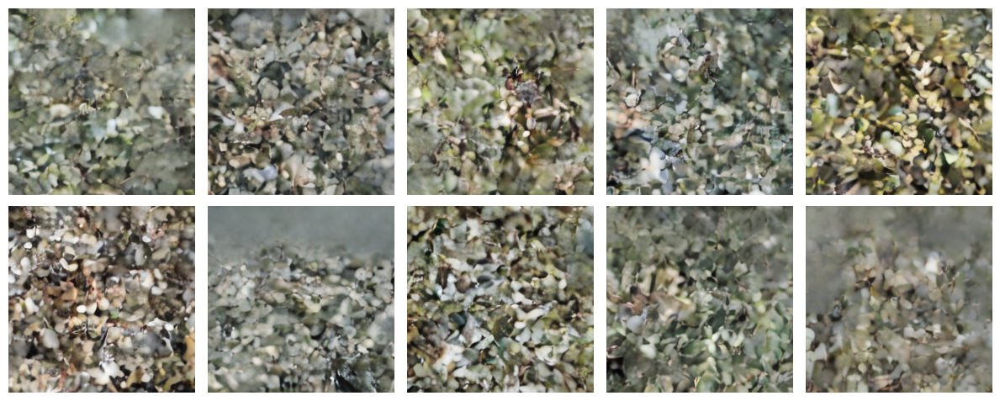

In [ ]:
# val_ds не нужен для проверки sanity, вместо него тот же sanity_ds
sanity_model_v2 = PixelCNNV2(
    num_codes=num_codes,
    optimizer_cls=torch.optim.Adam,
    optimizer_kwargs={"lr": 1e-3},
    scheduler_cls=None,
    c_hidden=160,
    embed_dim=64,
    head_dim=384,
    dilations = (1, 2, 4, 8, 4, 8, 4, 1, 2, 1)
)

sanity_model_v2, sanity_metrics = train_model(
    sanity_model_v2,
    sanity_ds, sanity_ds, test_ds,
    epochs=30, batch_size=32
)
show_samples(sanity_model_v2, vqvae, 32, 32, temperature=1, batch_size=10)

Генерация:   0%|          | 0/32 [00:00<?, ?it/s]

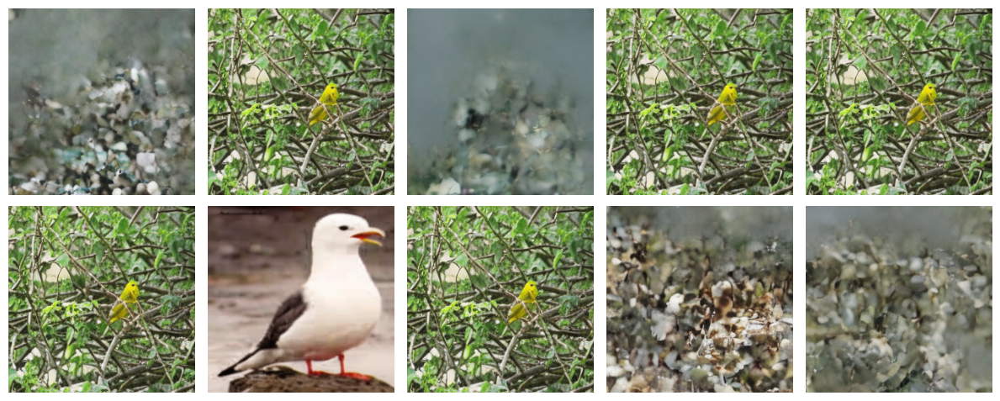

In [ ]:
show_samples(sanity_model_v2, vqvae, 32, 32, temperature=0.4, batch_size=10)

На изначальной архитектуре PixelCNN с семинара не получилось пройти даже sanity-check, на 100 эпохах bdp был около 5, а генерация даже с низкой температурой выдавала один лишь фон. Поэтому пришлось усложнить модель, добавив ей MLP на голову, а также LayerNorm как в AR моделях. При сэмплировании с высокой температурой модель также генерирует что-то невнятное, при понижении мы видим хорошие изображения птиц. Такое поведение скорее всего связано с тем, что мы не обучаем позиционные эмбеддинги, на картинках птицы находятся в основном посередине изображения.

Обучим на полном наборе данных

In [ ]:
torch.set_float32_matmul_precision("high")

pixel_cnn = PixelCNNV2(
  num_codes=num_codes,
  optimizer_cls=torch.optim.Adam,
  optimizer_kwargs={"lr": 1e-3},
  scheduler_cls=optim.lr_scheduler.StepLR,
  scheduler_kwargs={"step_size": 30, "gamma": 0.9},
  c_hidden=160,
  embed_dim=64,
  head_dim=384,
  dilations = (1, 2, 4, 8, 4, 8, 4, 1, 2, 1)
)

model, metrics = train_model(
    pixel_cnn,
    train_ds, val_ds, test_ds,
    epochs=150, batch_size=32
)
show_samples(model, vqvae, 32, 32, temperature=0.6, batch_size=10)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type                       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ embedding │ Embedding                  │  262 K │ train │     0 │
│ 1 │ first_v   │ VerticalStackConvolution   │ 92.3 K │ train │     0 │
│ 2 │ first_h   │ HorizontalStackConvolution │ 30.9 K │ train │     0 │
│ 3 │ blocks    │ ModuleList                 │  7.2 M │ train │     0 │
│ 4 │ head      │ Sequential                 │  1.6 M │ train │     0 │
└───┴───────────┴────────────────────────────┴────────┴───────┴───────┘

Trainable params: 9.2 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 9.2 M                                                                                                
Total estimated model params size (MB): 36.847                                                                     
Modules in train mode: 111                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

In [ ]:
callback = pixel_cnn.trainer.checkpoint_callback
ckpt_path = callback.last_model_path or callback.best_model_path
print(f"Продолжаем с: {ckpt_path}")

continued_model = PixelCNN.load_from_checkpoint(
    ckpt_path,
    map_location="cpu",
    weights_only=False,
    optimizer_cls=torch.optim.Adam,
    optimizer_kwargs={"lr": 4e-4},
    scheduler_cls=None,
    scheduler_kwargs={},
)

continued_model, continued_metrics = train_model(
    continued_model,
    train_ds, val_ds, test_ds, vqvae,
    epochs=15,
    batch_size=64,
)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Продолжаем с: saved_models/ar_models/PixelCNN/lightning_logs/version_5/checkpoints/epoch=81-step=10906.ckpt


┏━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name        ┃ Type                       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ embedding   │ Embedding                  │  131 K │ train │     0 │
│ 1 │ conv_vstack │ VerticalStackConvolution   │ 18.5 K │ train │     0 │
│ 2 │ conv_hstack │ HorizontalStackConvolution │  6.2 K │ train │     0 │
│ 3 │ conv_layers │ ModuleList                 │  834 K │ train │     0 │
│ 4 │ conv_out    │ Conv2d                     │  266 K │ train │     0 │
└───┴─────────────┴────────────────────────────┴────────┴───────┴───────┘

Trainable params: 1.3 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 1.3 M                                                                                                
Total estimated model params size (MB): 5.027                                                                      
Modules in train mode: 56                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=15` reached.


INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_bpd          │     10.17469596862793     │
└───────────────────────────┴───────────────────────────┘

Генерация:   0%|          | 0/32 [00:00<?, ?it/s]

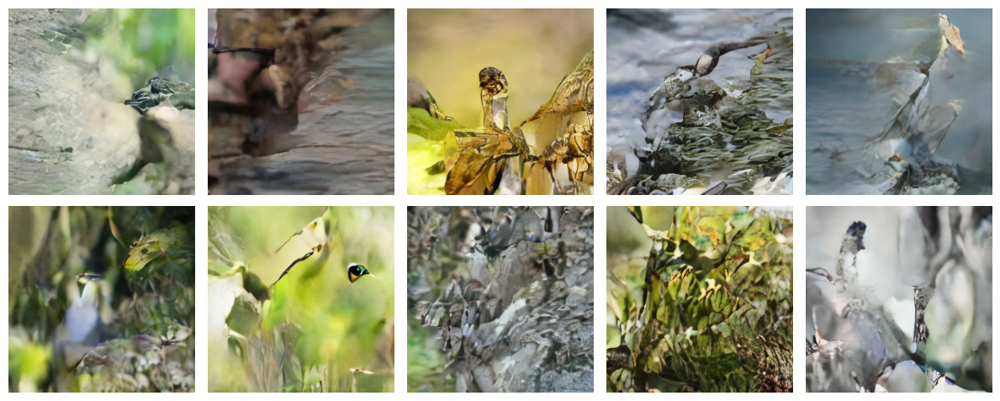

In [ ]:
show_samples(continued_model, vqvae, 32, 32, temperature=1, batch_size=10)

### Задание 5 (3.5 балла).

- Добавьте сохраненные эмбеддинги подписей к архитектуре PixelCNN (это можно сделать любым способом - прибавить эмбеддинги, сконкатенировать их, использовать cross-attention или любой другой подход).

- Обучите такую conditional-модель на птицах и эмбеддингах текстов, выведите на экран по 10 промптам, похожим по формату на промпты из трейна, сгенерированные картинки. Оцените результат, напишите выводы (здесь вы тоже можете менять гиперпараметры модели)

**Hint:** для улучшения качества в последующих заданиях можете прочитать сначала условие задания 6

In [ ]:
 # ваш код здесь

### Задание 6 (0.5 балла).

Добавьте [classifier-free guidance](https://colab.research.google.com/drive/1EIsBxlTcz3ZB0j-ZxN1gWD2dSQq6krPj?usp=sharing) на этапе инференса для увеличения разнообразия генерации. Проведите несколько экспериментов.

Для улучшения качества и разнообразия генерации (опционально) можно добавить [classifier-free guidance и на этапе обучения](https://education.yandex.ru/handbook/ml/article/diffuzionnye-modeli):
- для этого во время обучения эмбеддинг промпта заменяется с какой-то фиксированной вероятностью (например, 10%) на эмбеддинг пустого промпта



In [ ]:
# ваш код здесь

### Задание 7 (0.5 балла)

Реализуйте какую-нибудь метрику качества генерации - на ваш выбор (это может быть Inception Score, Frechet Inception Distance, LPIPS или что-то другое). Вам необходимо привести работающий код для вычисления метрики и текстом пояснить как работает метрика.

Далее вычислите значение этой метрики для обученной в задании 5 модели и сделайте выводы.

In [ ]:
# ваш код здесь

### Задание 8 (0.5 балла).

Можете делать любые действия для улучшения работы вашей модели (менять число слоев, параметры архитектуры - не отходя от концепции PixelCNN, менять гиперпараметры, делать аугментацию изображений и текстов и так далее).

Проведите эксперименты по улучшению качества модели - оценивайте качество модели с точки зрения:
- Реализованной в задании 7 метрики
- Визуально.

Мы ожидаем, что качество может не вырасти, но и не упадет.

In [ ]:
# ваш код здесь

### Задание 9 (1.5 балла).

Проанализируйте лучшую модель:

- Придумайте 5 разных признаков (например, цвет, вид оперения, длина клюва, лап и так далее) и посмотрите, будет ли модель их понимать благодаря текстовому эмбеддингу? (0.5 балла)

- Попробуйте добавлять в модель другие промпты - не связанные с птицами, или по-другому построенные (не "a photo of", а по-другому сформулированные). Как отрабатывает модель? (0.5 балла)

- Фиксируйте удачный промпт и проведите эксперименты по изменению веса guidance в classifer-free подходе. Сделайте выводы. (0.5 балла)

In [ ]:
# ваш код здесь